# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data.

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


**Question 1:** Unlike Random Forests and Gradient Boosting, neural networks need the features to be scaled. A neural network learns by using gradient descent to update its weights, so features with really large values end up dominating those updates, which makes training slower and less stable. This matters a lot for this dataset because the features range from 0 all the way up to about 2.1 billion. Seven of the columns, like http_time_sum and http_dom_host_alexaRank, have a max value of 2,147,483,647, which is the largest number a 32-bit integer can hold, so it is probably being used as a placeholder value. Because of this, we standardized the features using StandardScaler.

We put the StandardScaler inside a Pipeline with the MLPClassifier so that the scaler is only fit on the training data in each cross-validation fold, which avoids data leakage. Other preprocessing steps were not needed because the target variable was already encoded with the Label Encoder in Part 1, there are no missing values, and all of the input features are already numeric.

In [13]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [14]:
mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(max_iter=300,
                          early_stopping=True,
                          validation_fraction=0.1,
                          n_iter_no_change=10,
                          random_state=42))
])

mlp_params = {
    "mlp__hidden_layer_sizes": [(32,), (64,), (128,),
                                (32, 32), (64, 64), (128, 128),
                                (32, 32, 32), (64, 64, 64), (128, 128, 128)]
}

mlp_grid = GridSearchCV(mlp_pipe, mlp_params, cv=cv, scoring='accuracy', n_jobs=-1)

start = time.time()
mlp_grid.fit(X_train_df, y_train_df)
mlp_time = (time.time() - start)/60

print(f"Best parameters: {mlp_grid.best_params_}\nBest Cross Validation Accuracy: {mlp_grid.best_score_:.4f}\nSearch Time: {mlp_time:.2f} minutes")

Best parameters: {'mlp__hidden_layer_sizes': (64, 64, 64)}
Best Cross Validation Accuracy: 0.8433
Search Time: 0.25 minutes


In [15]:
pd.DataFrame(mlp_grid.cv_results_)[['param_mlp__hidden_layer_sizes', 'mean_test_score', 'std_test_score']] \
    .sort_values('mean_test_score', ascending=False)

,param_mlp__hidden_layer_sizes,mean_test_score,std_test_score
7,"(64, 64, 64)",0.843333,0.022608
8,"(128, 128, 128)",0.843333,0.022055
5,"(128, 128)",0.842222,0.030348
3,"(32, 32)",0.838889,0.028328
2,"(128,)",0.830000,0.023465
6,"(32, 32, 32)",0.830000,0.014316
4,"(64, 64)",0.826667,0.019052
1,"(64,)",0.824444,0.015154
0,"(32,)",0.814444,0.052068


In [16]:
mlp_best = mlp_grid.best_estimator_
mlp_pred = mlp_best.predict(X_report_df)

print(f"Reporting Accuracy: {accuracy_score(y_report_df, mlp_pred):.4f}\n")
print("MLP\n", classification_report(y_report_df, mlp_pred, target_names=le.classes_, zero_division=0))

Reporting Accuracy: 0.1800

MLP
                  precision    recall  f1-score   support

             TV       0.29      0.10      0.15       100
   baby_monitor       0.04      0.12      0.07       100
         lights       0.00      0.00      0.00       100
  motion_sensor       0.06      0.02      0.03       100
security_camera       0.08      0.16      0.11       100
 smoke_detector       0.89      0.50      0.64       100
         socket       0.45      0.70      0.55       100
     thermostat       0.02      0.01      0.01       100
          watch       0.01      0.01      0.01       100

       accuracy                           0.18       900
      macro avg       0.20      0.18      0.17       900
   weighted avg       0.20      0.18      0.17       900



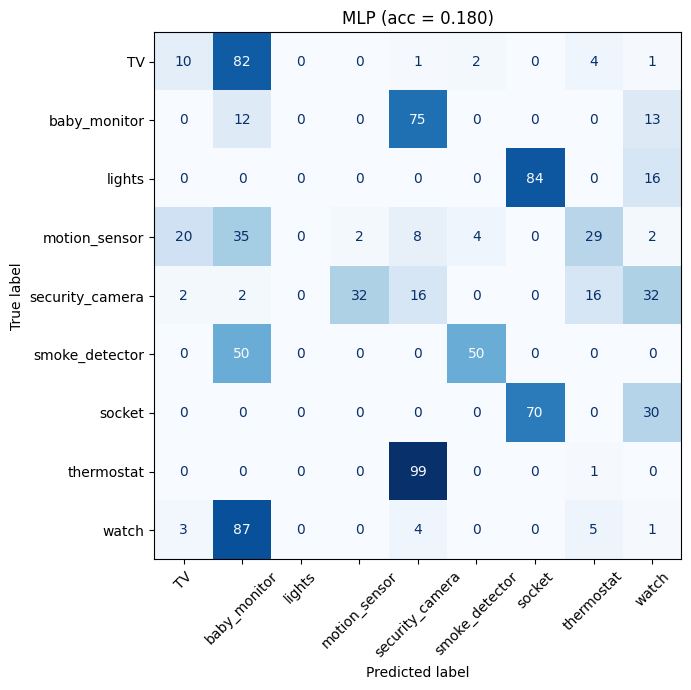

In [17]:
mlp_cm = confusion_matrix(y_report_df, mlp_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(mlp_cm, display_labels=le.classes_).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title(f'MLP (acc = {accuracy_score(y_report_df, mlp_pred):.3f})')
plt.tight_layout()
plt.show()

In [20]:
comparison = pd.DataFrame({
    'Model': ['Gradient Boosting', 'Random Forest', 'MLP'],
    'CV Accuracy': [0.8900, 0.8878, mlp_grid.best_score_],
    'Reporting Accuracy': [0.6811, 0.6756, accuracy_score(y_report_df, mlp_pred)],
    'Search Time in Minutes': [3.69, 0.10, mlp_time]
})
comparison

,Model,CV Accuracy,Reporting Accuracy,Search Time in Minutes
0,Gradient Boosting,0.890000,0.6811,3.690000
1,Random Forest,0.887800,0.6756,0.100000
2,MLP,0.843333,0.1800,0.248531


**Question 3:** The MLP got a cross-validation accuracy of 0.843, close to Gradient Boosting (0.890) and Random Forest (0.888), but on the reporting data it only got 18% compared to around 68% for both ensembles. That is barely better than the 11.1% random guessing baseline. All the models dropped on the reporting data, but the MLP dropped the most, likely because neural networks depend on feature scale while trees just split on thresholds. The MLP is also harder to interpret since it has about 28,000 weights and works like a black box, while the ensemble models give feature importances. Overall, the ensemble methods were more accurate and easier to interpret, so the neural network was not worth the extra complexity.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE